# COU07506 DSP Laboratory — Week 1
Name:REVOLD SEVELINE KABATITI
Registration number:240242421733
Date:23/11/2026
Group:

## Task 1.1 — Elementary Discrete-Time Signals

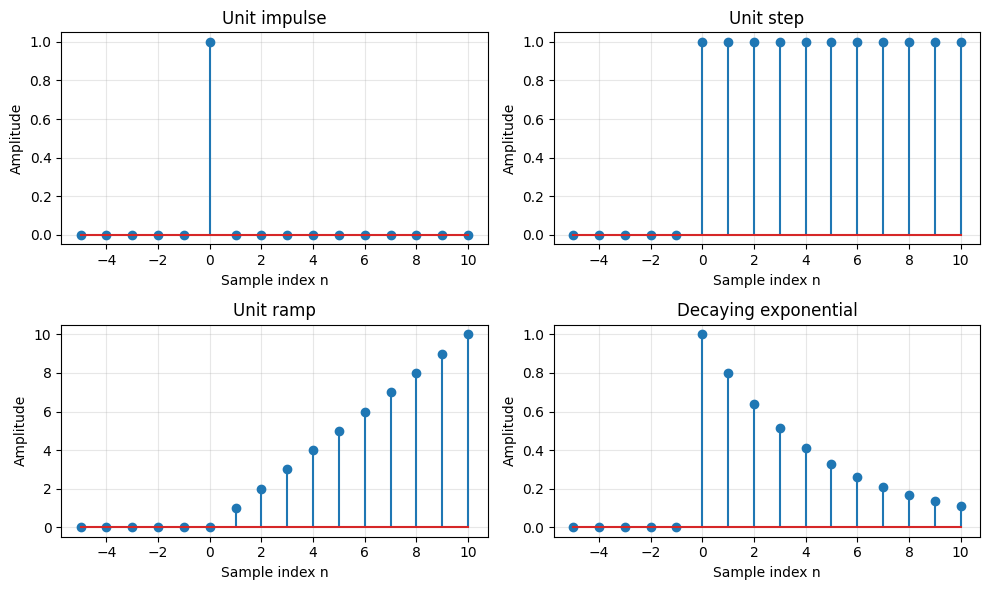

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)       # Sample indices from -5 through 10
impulse = (n == 0).astype(int)
step = (n >= 0).astype(int)
ramp = n * step
exponential = 0.8**n * step

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

signals = [
    ("Unit impulse", impulse),
    ("Unit step", step),
    ("Unit ramp", ramp),
    ("Decaying exponential", exponential),
]

for ax, (title, values) in zip(axes.flat, signals):
    ax.stem(n, values)
    ax.set_title(title)
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Task 1.2 — Exponentials and Periodicity

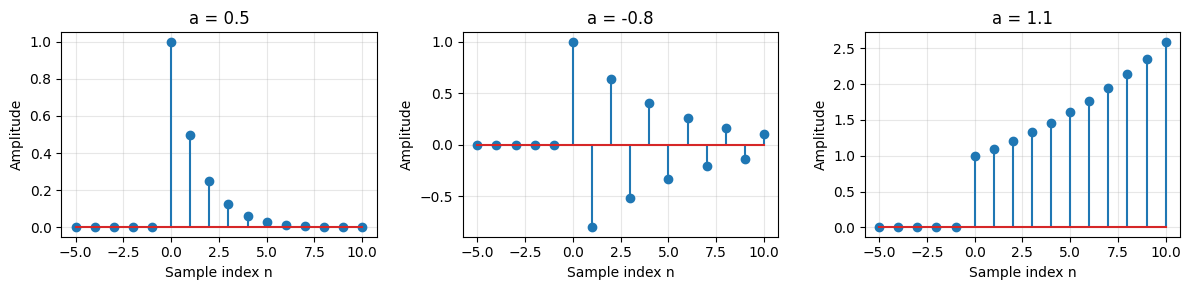

In [2]:
n = np.arange(-5, 11)
u = (n >= 0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * u)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index n")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

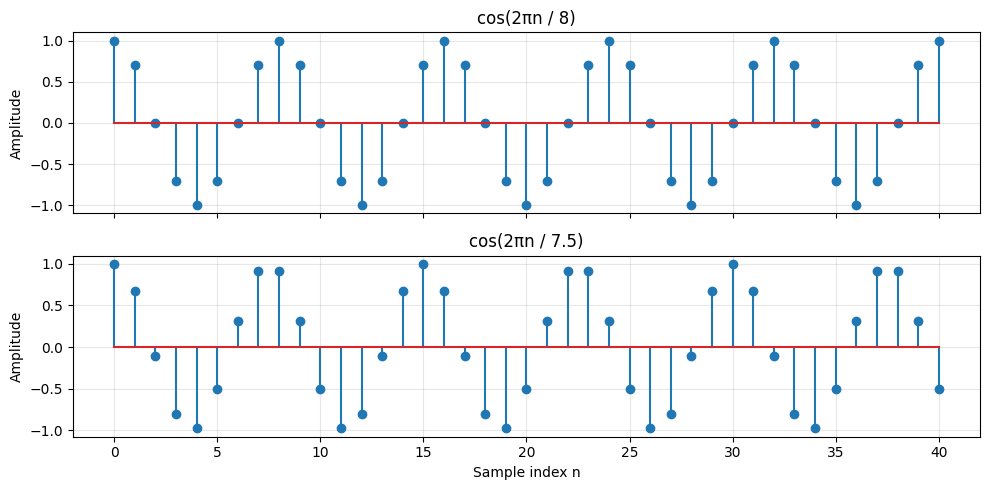

In [3]:
n = np.arange(41)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

for ax, d in zip(axes, [8, 7.5]):
    ax.stem(n, np.cos(2 * np.pi * n / d))
    ax.set_title(f"cos(2πn / {d})")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()

## Task 1.3 — Voice Recording

In [13]:
from google.colab import files
uploaded = files.upload()

Saving my_voice.wav.wav to my_voice.wav (2).wav


Sampling rate: 48,000 Hz
Duration: 4.14 seconds
Number of mono samples: 198,720
Samples in one minute of mono audio: 2,880,000


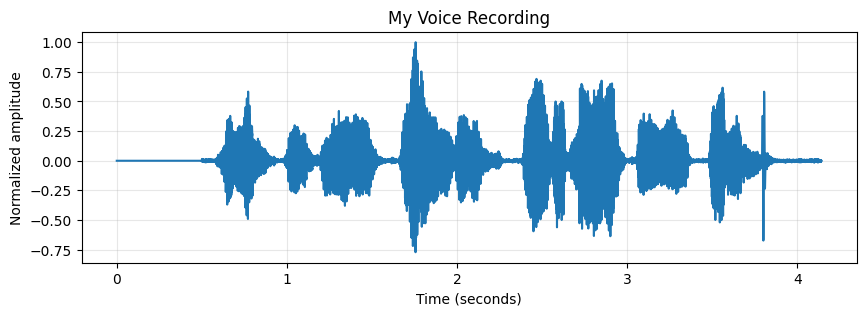

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display

fs, recording = wavfile.read("my_voice.wav (2).wav")

x = recording.astype(float)
if recording.dtype == np.uint8:
    x -= 128
if x.ndim == 2:
    x = x.mean(axis=1)  # Convert stereo to mono

peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

t = np.arange(len(x)) / fs

print(f"Sampling rate: {fs:,} Hz")
print(f"Duration: {len(x) / fs:.2f} seconds")
print(f"Number of mono samples: {len(x):,}")
print(f"Samples in one minute of mono audio: {60 * fs:,}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.title("My Voice Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.grid(alpha=0.3)
plt.show()

display(Audio(x, rate=fs, normalize=False))

## Task 1.5 — Git Repository
https://github.com/ryantrent211-debug/COU07506-labs